<a href="https://colab.research.google.com/github/akatsushikami-arch/HW/blob/main/KNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from keras.datasets import mnist, fashion_mnist, cifar10
from collections import Counter
from sklearn.metrics import accuracy_score

In [ ]:
class KNN:
    def __init__(self, k=3):
        self.k = k
        self.X_train = None
        self.y_train = None
        self.X_test = None
        self.y_test = None

    def fit(self, X_train, y_train):
        self.X_train = X_train.reshape(X_train.shape[0], -1).astype(np.float32)
        self.y_train = np.asarray(y_train)
        return self

    def predict_one(self, x):
        dists = np.sqrt(np.sum((self.X_train - x) ** 2, axis=1))
        k_idx = np.argsort(dists)[: self.k]
        k_labels = self.y_train[k_idx]
        return Counter(k_labels).most_common(1)[0][0]

    def predict(self, X):
        X = X.reshape(X.shape[0], -1).astype(np.float32)
        return np.array([self.predict_one(x) for x in X])

In [ ]:
def evaluate_and_show_errors(model, X_test, y_test, class_names,
                             dataset_name="dataset", n_errors=10):

    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"Точность: {acc:.4f}  ({np.sum(y_pred == y_test)}/{len(y_test)})")

    errors_idx = np.where(y_pred != y_test)[0]
    print(f"Количество ошибок: {len(errors_idx)}")

    if len(errors_idx) > 0:
        n_show = min(n_errors, len(errors_idx))
        plt.figure(figsize=(15, 3))
        for i, idx in enumerate(errors_idx[:n_show]):
            plt.subplot(1, n_show, i + 1)
            img = X_test[idx]
            if img.ndim == 2:
                plt.imshow(img, cmap="gray")
            else:
                plt.imshow(img)
            plt.title(f"правильно: {class_names[y_test[idx]]}\n"
                      f"предположено: {class_names[y_pred[idx]]}",
                      fontsize=8)
        plt.suptitle(f"Примеры ошибок в {dataset_name}")
        plt.tight_layout()
        plt.show()

    return y_pred, acc, errors_idx

MNIST: (60000, 28, 28) (10000, 28, 28)
Точность: 0.9367  (281/300)
Количество ошибок: 19


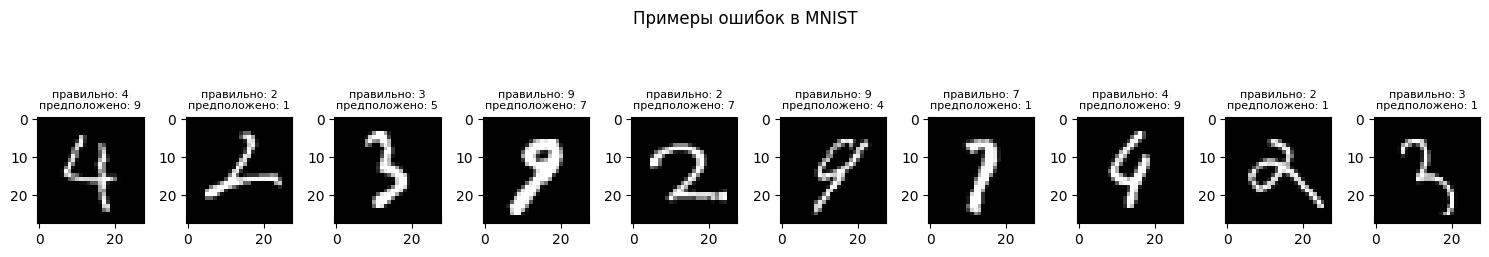

In [ ]:
(Xtr, ytr), (Xte, yte) = mnist.load_data()
print("MNIST:", Xtr.shape, Xte.shape)

n_train, n_test = 5000, 300
mnist_names = [str(i) for i in range(10)]

knn_mnist = KNN(k=3)
knn_mnist.fit(Xtr[:n_train], ytr[:n_train])

_, acc_mnist, err_mnist = evaluate_and_show_errors(knn_mnist, Xte[:n_test], yte[:n_test], class_names=mnist_names, dataset_name="MNIST")


Fashion-MNIST: (60000, 28, 28) (10000, 28, 28)
Точность: 0.8400  (252/300)
Количество ошибок: 48


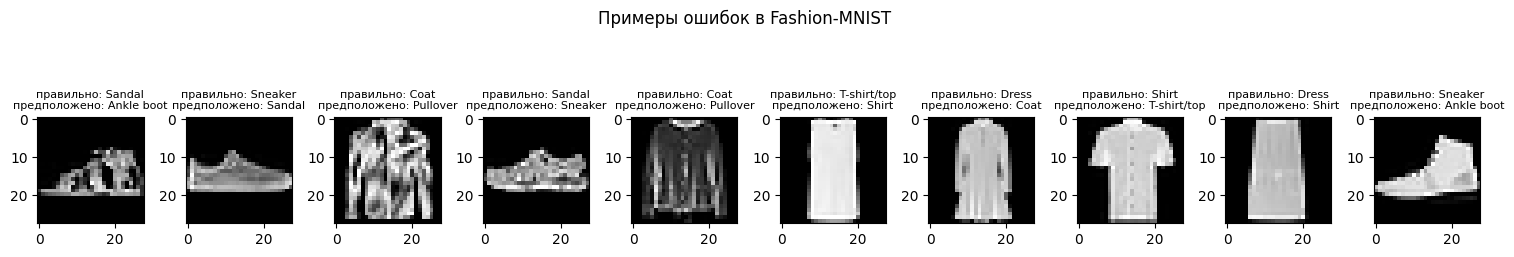

In [ ]:
(Xtr_f, ytr_f), (Xte_f, yte_f) = fashion_mnist.load_data()
print("\nFashion-MNIST:", Xtr_f.shape, Xte_f.shape)

fashion_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

knn_fashion = KNN(k=3)
knn_fashion.fit(Xtr_f[:n_train], ytr_f[:n_train])

_, acc_fashion, err_fashion = evaluate_and_show_errors(knn_fashion, Xte_f[:n_test], yte_f[:n_test], class_names=fashion_names, dataset_name="Fashion-MNIST")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2863s 17us/step

CIFAR-10: (50000, 32, 32, 3) (10000, 32, 32, 3)
Точность: 0.3100  (31/100)
Количество ошибок: 69


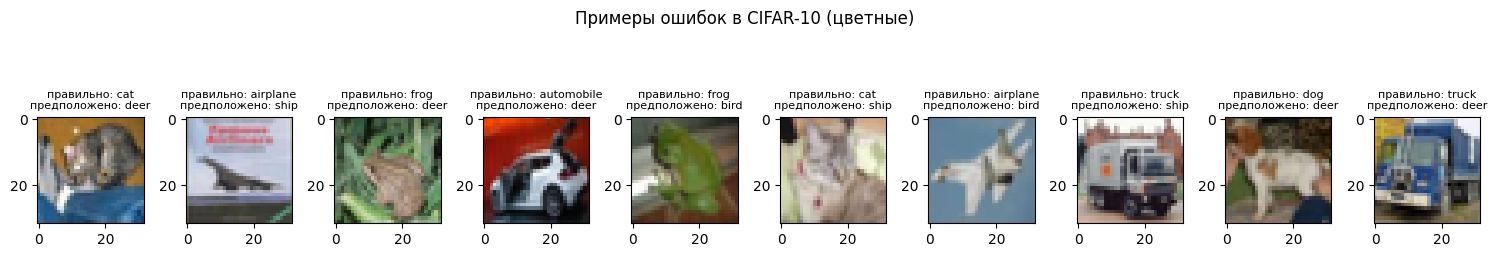

In [ ]:
(Xtr_c, ytr_c), (Xte_c, yte_c) = cifar10.load_data()
ytr_c = ytr_c.flatten()
yte_c = yte_c.flatten()
print("\nCIFAR-10:", Xtr_c.shape, Xte_c.shape)

cifar_names = [
    "airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

knn_cifar = KNN(k=3)
knn_cifar.fit(Xtr_c[:2000], ytr_c[:2000])

_, acc_cifar, err_cifar = evaluate_and_show_errors(knn_cifar, Xte_c[:100], yte_c[:100], class_names=cifar_names, dataset_name="CIFAR-10 (цветные)")

In [ ]:
results = {
    "MNIST (ч/б, цифры)": acc_mnist,
    "Fashion-MNIST (ч/б, вещи)": acc_fashion,
    "CIFAR-10 (цветные)": acc_cifar,}
for name, acc in results.items():
    print(f"{name} = {acc:.4f} = {acc*100}%")

MNIST (ч/б, цифры) = 0.9367 = 93.66666666666667%
Fashion-MNIST (ч/б, вещи) = 0.8400 = 84.0%
CIFAR-10 (цветные) = 0.3100 = 31.0%
